# 84 · Project 6: single-step BC vs chunked regression vs ACT vs Diffusion vs Flow: same data, same harness

In [1]:
import os, json, time, numpy as np, torch, matplotlib.pyplot as plt
from vlacourse import TableTop, evaluate
from vlacourse.torch_data import TableTopDataset
from vlacourse.chunk_policies import ChunkRegression, ACT, DiffusionPolicy, FlowPolicy, ChunkPolicy

from vlacourse import scene_dataset
SCENE = "single"                    # TableTop scene tier (see vlacourse.SCENES)
DATA = scene_dataset(SCENE)          # 500 demos, recorded once with all CPU cores if missing
device = "cuda" if torch.cuda.is_available() else "cpu"
H, N_EVAL = 16, 100

def load(cls, path, horizon):
    net = cls(horizon=horizon); net.load_state_dict(torch.load(path, map_location=device)); return net.to(device).eval()

def shift_camera(env, obs, a):
    if env.t == 0:
        cid = env.model.camera("front").id
        env.model.cam_pos[cid] = BASE_CAM + np.array([0.0, 0.04, -0.03])
    return a

In [2]:
ds1 = TableTopDataset(DATA, episodes=range(450), horizon=1)
ds16 = TableTopDataset(DATA, episodes=range(450), horizon=H)
env = TableTop(scene=SCENE, cameras=("front", "wrist"), image_size=(128, 128), seed=0)
BASE_CAM = env.model.cam_pos[env.model.camera("front").id].copy()
policies = {
    "single-step regression": ChunkPolicy(load(ChunkRegression, "checkpoints/chunkreg_H1.pt", 1), ds1, env, device, execute=1),
    "chunked regression (H=16)": ChunkPolicy(load(ChunkRegression, "checkpoints/chunkreg_H16.pt", H), ds16, env, device, ensemble=True),
    "ACT (CVAE transformer)": ChunkPolicy(load(ACT, "checkpoints/act.pt", H), ds16, env, device, ensemble=True),
    "Diffusion Policy (DDIM 10)": ChunkPolicy(load(DiffusionPolicy, "checkpoints/diffusion.pt", H), ds16, env, device, execute=8, nfe=10),
    "Flow matching (Euler 4)": ChunkPolicy(load(FlowPolicy, "checkpoints/flow.pt", H), ds16, env, device, execute=8, nfe=4),
}

vlacourse/chunk_policies.py:76: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  enc = lambda: nn.TransformerEncoder(nn.TransformerEncoderLayer(d, 8, 4 * d, 0.1, batch_first=True, norm_first=True), layers)


In [3]:
results = {}
for name, pol in policies.items():
    t0 = time.time()
    nominal = evaluate(env, pol, n_episodes=N_EVAL, seed=70_000)
    shifted = evaluate(env, pol, n_episodes=50, seed=71_000, on_step=shift_camera)
    env.model.cam_pos[env.model.camera("front").id] = BASE_CAM
    results[name] = dict(nominal=nominal["success"], ci=nominal["ci"], per_task=nominal["per_task"], shifted=shifted["success"], shifted_ci=shifted["ci"])
    print(f"{name:28s} nominal {nominal['success']:.2f} [{nominal['ci'][0]:.2f},{nominal['ci'][1]:.2f}]  camera moved {shifted['success']:.2f}   per task {nominal['per_task']}  ({time.time() - t0:.0f}s)")

single-step regression       nominal 0.07 [0.03,0.14]  camera moved 0.20   per task {'place': 0.02, 'pick': 0.12}  (1004s)


chunked regression (H=16)    nominal 1.00 [0.96,1.00]  camera moved 0.98   per task {'place': 1.0, 'pick': 1.0}  (214s)


ACT (CVAE transformer)       nominal 0.96 [0.90,0.98]  camera moved 1.00   per task {'place': 0.96, 'pick': 0.96}  (222s)


Diffusion Policy (DDIM 10)   nominal 0.93 [0.86,0.97]  camera moved 0.94   per task {'place': 0.92, 'pick': 0.94}  (180s)


Flow matching (Euler 4)      nominal 0.99 [0.95,1.00]  camera moved 1.00   per task {'place': 0.98, 'pick': 1.0}  (79s)


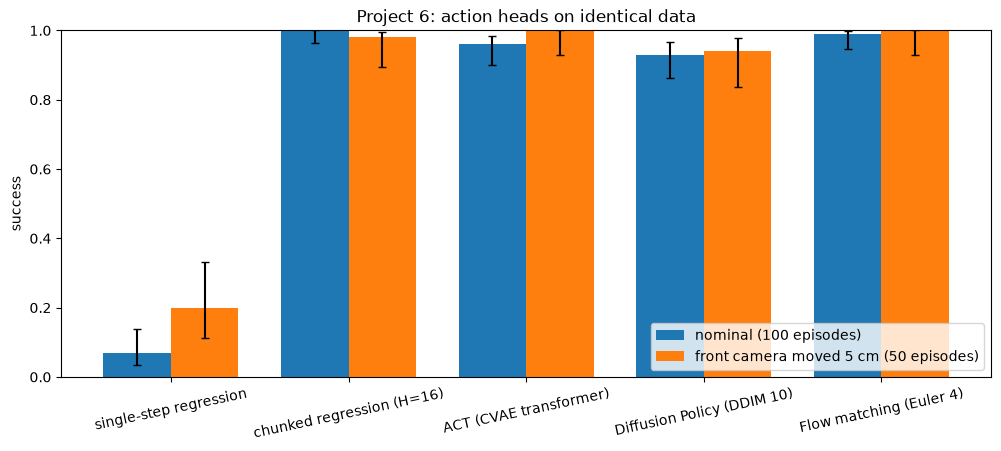

In [4]:
names = list(results)
x = np.arange(len(names)); w = 0.38
nom = np.array([results[n]["nominal"] for n in names]); sh = np.array([results[n]["shifted"] for n in names])
nci = np.array([results[n]["ci"] for n in names]); sci = np.array([results[n]["shifted_ci"] for n in names])
plt.figure(figsize=(12, 4.5))
plt.bar(x - w / 2, nom, w, yerr=[nom - nci[:, 0], nci[:, 1] - nom], capsize=3, label=f"nominal ({N_EVAL} episodes)")
plt.bar(x + w / 2, sh, w, yerr=[sh - sci[:, 0], sci[:, 1] - sh], capsize=3, label="front camera moved 5 cm (50 episodes)")
plt.xticks(x, names, rotation=12); plt.ylim(0, 1); plt.ylabel("success"); plt.legend(); plt.title("Project 6: action heads on identical data"); plt.show()

In [5]:
os.makedirs("results", exist_ok=True)
json.dump(results, open("results/project6_heads.json", "w"), indent=1)
print("saved results/project6_heads.json")

saved results/project6_heads.json


### The finale: five action heads, one episode
Identical data, encoder and episode; only the action head differs.

In [6]:
from vlacourse import showcase as sc
sc.compare(env, policies, seed=70_001, size=(270, 360), title="84 five action heads, same episode")

84 five action heads, same episode: single-step regression: failed | chunked regression (H=16): success | ACT (CVAE transformer): success | Diffusion Policy (DDIM 10): success | Flow matching (Euler 4): success


[False, True, True, True, True]